In [1]:
%pip install pytorch-msssim -q
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np, json, os
from pathlib import Path
from pytorch_msssim import ssim as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
from skimage.metrics import structural_similarity as ssim_sk

DATA_ROOT  = '/kaggle/input/datasets/tushar72345/qsyncardiotwin-v2/qsyncardiotwin_v2/patients'
MANIFEST   = '/kaggle/input/datasets/tushar72345/qsyncardiotwin-v2/qsyncardiotwin_v2/split_manifest.json'
OUTPUT_DIR = '/kaggle/working/training_output_v2'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Setup done")

Note: you may need to restart the kernel to use updated packages.
Setup done


In [2]:
class CardiacMRIDataset(Dataset):
    def __init__(self, patient_dirs, accel=4):
        self.samples = []; self.accel = accel
        for pd in patient_dirs:
            pd = Path(pd)
            if (pd/f'kspace_R{accel}.npz').exists() and (pd/'kspace_full.npz').exists():
                self.samples.append(pd)
    def __len__(self): return len(self.samples)
    def rss(self, k):
        imgs = np.fft.ifftshift(np.fft.ifft2(np.fft.ifftshift(k, axes=(-2,-1)), axes=(-2,-1)), axes=(-2,-1))
        return np.sqrt(np.sum(np.abs(imgs)**2, axis=0)).astype(np.float32)
    def __getitem__(self, idx):
        pd = self.samples[idx]
        us   = self.rss(np.load(pd/f'kspace_R{self.accel}.npz')['kspace'])
        full = self.rss(np.load(pd/'kspace_full.npz')['kspace'])
        us   = us/(us.max()+1e-8); full = full/(full.max()+1e-8)
        return torch.from_numpy(us).unsqueeze(0), torch.from_numpy(full).unsqueeze(0)

with open(MANIFEST) as f: manifest = json.load(f)
def get_dirs(split): return [f'{DATA_ROOT}/{p}' for p,v in manifest.items() if v['split']==split]

train_dl = DataLoader(CardiacMRIDataset(get_dirs('train')), batch_size=16, shuffle=True,  num_workers=2)
val_dl   = DataLoader(CardiacMRIDataset(get_dirs('val')),   batch_size=16, shuffle=False, num_workers=2)
test_dl  = DataLoader(CardiacMRIDataset(get_dirs('test')),  batch_size=16, shuffle=False, num_workers=2)
print(f"Train:{len(train_dl.dataset)} Val:{len(val_dl.dataset)} Test:{len(test_dl.dataset)}")

Train:348 Val:72 Test:80


In [3]:
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):
        return x * self.psi(F.relu(self.W_g(g) + self.W_x(x)))

class ConvBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, features=[64,128,256,512]):
        super().__init__()
        self.encoders = nn.ModuleList(); self.pools = nn.ModuleList()
        ch = in_ch
        for f in features:
            self.encoders.append(ConvBlock(ch, f)); self.pools.append(nn.MaxPool2d(2)); ch = f
        self.bottleneck = ConvBlock(ch, ch*2)
        self.upconvs = nn.ModuleList(); self.attn = nn.ModuleList(); self.decoders = nn.ModuleList()
        enc_ch = ch*2
        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(enc_ch, f, 2, stride=2))
            self.attn.append(AttentionGate(f, f, f//2))
            self.decoders.append(ConvBlock(f*2, f)); enc_ch = f
        self.final = nn.Conv2d(features[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for enc, pool in zip(self.encoders, self.pools):
            x = enc(x); skips.append(x); x = pool(x)
        x = self.bottleneck(x)
        for up, attn, dec, skip in zip(self.upconvs, self.attn, self.decoders, reversed(skips)):
            x = up(x); skip = attn(x, skip); x = dec(torch.cat([x, skip], 1))
        return torch.sigmoid(self.final(x))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = AttentionUNet().to(device)
print(f"Device: {device} | Params: {sum(p.numel() for p in model.parameters()):,}")

Device: cuda | Params: 31,393,901


In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

def metrics(pred, target):
    p,t = pred.detach().cpu().numpy(), target.detach().cpu().numpy()
    ps,ss,ns = [],[],[]
    for a,b in zip(p,t):
        a,b = a[0],b[0]
        ps.append(psnr_fn(b,a,data_range=1.0))
        ss.append(ssim_sk(b,a,data_range=1.0))
        ns.append(np.sum((b-a)**2)/(np.sum(b**2)+1e-8))
    return np.mean(ps), np.mean(ss), np.mean(ns)

best_ssim, history = 0, []
for epoch in range(1, 51):
    model.train(); tloss = 0
    for us, full in train_dl:
        us, full = us.to(device), full.to(device)
        pred = model(us)
        loss = F.l1_loss(pred, full) + (1 - ssim_fn(pred, full, data_range=1.0))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        tloss += loss.item()
    tloss /= len(train_dl)
    model.eval(); vp,vs,vn = [],[],[]
    with torch.no_grad():
        for us, full in val_dl:
            us, full = us.to(device), full.to(device)
            p,s,n = metrics(model(us), full)
            vp.append(p); vs.append(s); vn.append(n)
    vp,vs,vn = np.mean(vp),np.mean(vs),np.mean(vn)
    scheduler.step(1-vs)
    history.append({'epoch':epoch,'loss':float(tloss),'psnr':float(vp),'ssim':float(vs),'nmse':float(vn)})
    if vs > best_ssim:
        best_ssim = vs
        torch.save(model.state_dict(), f'{OUTPUT_DIR}/best_model.pth')
    if epoch%5==0 or epoch==1:
        print(f"Ep {epoch:02d} | Loss {tloss:.4f} | PSNR {vp:.2f} | SSIM {vs:.4f} | NMSE {vn:.4f}")

with open(f'{OUTPUT_DIR}/history.json','w') as f: json.dump(history,f)
print(f"\nTraining complete! Best SSIM: {best_ssim:.4f}")

Ep 01 | Loss 1.2168 | PSNR 5.98 | SSIM 0.1682 | NMSE 0.8750
Ep 05 | Loss 0.8713 | PSNR 15.31 | SSIM 0.3073 | NMSE 0.1025
Ep 10 | Loss 0.7891 | PSNR 18.10 | SSIM 0.3474 | NMSE 0.0539
Ep 15 | Loss 0.7439 | PSNR 20.23 | SSIM 0.3634 | NMSE 0.0331
Ep 20 | Loss 0.6603 | PSNR 16.39 | SSIM 0.4730 | NMSE 0.0798
Ep 25 | Loss 0.5445 | PSNR 17.32 | SSIM 0.5601 | NMSE 0.0644
Ep 30 | Loss 0.4186 | PSNR 18.67 | SSIM 0.6594 | NMSE 0.0490
Ep 35 | Loss 0.2875 | PSNR 16.71 | SSIM 0.7832 | NMSE 0.0743
Ep 40 | Loss 0.1707 | PSNR 19.64 | SSIM 0.8417 | NMSE 0.0380
Ep 45 | Loss 0.0998 | PSNR 21.40 | SSIM 0.8951 | NMSE 0.0253
Ep 50 | Loss 0.0683 | PSNR 22.54 | SSIM 0.9222 | NMSE 0.0195

Training complete! Best SSIM: 0.9222


In [5]:
model.load_state_dict(torch.load(f'{OUTPUT_DIR}/best_model.pth'))
model.eval()

# R=4 test
tp,ts,tn = [],[],[]
with torch.no_grad():
    for us,full in test_dl:
        us,full = us.to(device),full.to(device)
        p,s,n = metrics(model(us),full)
        tp.append(p); ts.append(s); tn.append(n)
print(f"Test R=4 | PSNR:{np.mean(tp):.4f} | SSIM:{np.mean(ts):.4f} | NMSE:{np.mean(tn):.4f}")

# All R factors
all_results = {}
for R in [4,8,10,12]:
    ds = CardiacMRIDataset(get_dirs('test'), accel=R)
    dl = DataLoader(ds, batch_size=16, shuffle=False, num_workers=2)
    tp,ts,tn = [],[],[]
    with torch.no_grad():
        for us,full in dl:
            us,full = us.to(device),full.to(device)
            p,s,n = metrics(model(us),full)
            tp.append(p); ts.append(s); tn.append(n)
    all_results[R] = {'psnr':float(np.mean(tp)),'ssim':float(np.mean(ts)),'nmse':float(np.mean(tn))}
    print(f"R={R:2d} | PSNR:{np.mean(tp):.4f} | SSIM:{np.mean(ts):.4f} | NMSE:{np.mean(tn):.4f}")

with open(f'{OUTPUT_DIR}/test_results.json','w') as f: json.dump(all_results,f)
print("Saved!")

Test R=4 | PSNR:22.5311 | SSIM:0.9215 | NMSE:0.0194
R= 4 | PSNR:22.5311 | SSIM:0.9215 | NMSE:0.0194
R= 8 | PSNR:22.1858 | SSIM:0.9137 | NMSE:0.0212
R=10 | PSNR:22.0227 | SSIM:0.9106 | NMSE:0.0221
R=12 | PSNR:21.7228 | SSIM:0.9048 | NMSE:0.0239
Saved!


In [6]:
fracs = [0.10, 0.25, 0.50, 0.75, 1.00]
c1_results = []
all_train = get_dirs('train')

for frac in fracs:
    n = max(1, int(len(all_train)*frac))
    subset = all_train[:n]
    dl = DataLoader(CardiacMRIDataset(subset), batch_size=16, shuffle=True, num_workers=2)
    m = AttentionUNet().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-4)
    best_s = 0
    for ep in range(52):
        m.train()
        for us,full in dl:
            us,full = us.to(device),full.to(device)
            loss = F.l1_loss(m(us),full) + (1-ssim_fn(m(us),full,data_range=1.0))
            opt.zero_grad(); loss.backward(); opt.step()
        m.eval(); ss=[]
        with torch.no_grad():
            for us,full in test_dl:
                us,full = us.to(device),full.to(device)
                _,s,_ = metrics(m(us),full); ss.append(s)
        best_s = max(best_s, np.mean(ss))
    c1_results.append({'frac':frac,'n_train':n,'ssim':float(best_s)})
    print(f"C1 frac={frac:.2f} n={n} SSIM={best_s:.4f}")

with open(f'{OUTPUT_DIR}/c1_scaling.json','w') as f: json.dump(c1_results,f)
print("C1 saved!")

C1 frac=0.10 n=34 SSIM=0.2834
C1 frac=0.25 n=87 SSIM=0.4403
C1 frac=0.50 n=174 SSIM=0.5718
C1 frac=0.75 n=261 SSIM=0.8227
C1 frac=1.00 n=348 SSIM=0.9334
C1 saved!


In [7]:
n_reals = [0, 5, 10, 20, 50]
c2_results = []

for n_real in n_reals:
    m = AttentionUNet().to(device)
    m.load_state_dict(torch.load(f'{OUTPUT_DIR}/best_model.pth'))
    if n_real > 0:
        real_subset = get_dirs('train')[:n_real]
        dl = DataLoader(CardiacMRIDataset(real_subset), batch_size=8, shuffle=True, num_workers=2)
        opt = torch.optim.Adam(m.parameters(), lr=1e-5)
        for ep in range(52):
            m.train()
            for us,full in dl:
                us,full = us.to(device),full.to(device)
                loss = F.l1_loss(m(us),full) + (1-ssim_fn(m(us),full,data_range=1.0))
                opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); ss=[]
    with torch.no_grad():
        for us,full in test_dl:
            us,full = us.to(device),full.to(device)
            _,s,_ = metrics(m(us),full); ss.append(s)
    c2_results.append({'n_real':n_real,'ssim':float(np.mean(ss))})
    print(f"C2 n_real={n_real:3d} SSIM={np.mean(ss):.4f}")

with open(f'{OUTPUT_DIR}/c2_transfer.json','w') as f: json.dump(c2_results,f)
print("C2 saved!")

C2 n_real=  0 SSIM=0.9215
C2 n_real=  5 SSIM=0.9151
C2 n_real= 10 SSIM=0.9180
C2 n_real= 20 SSIM=0.9205
C2 n_real= 50 SSIM=0.9233
C2 saved!


In [8]:
import matplotlib.pyplot as plt

# Fig 9
with open(f'{OUTPUT_DIR}/test_results.json') as f: res = json.load(f)
r_vals = [4,8,10,12]
psnr_v = [res[str(R)]['psnr'] for R in r_vals]
ssim_v = [res[str(R)]['ssim'] for R in r_vals]
nmse_v = [res[str(R)]['nmse'] for R in r_vals]

fig, axes = plt.subplots(1,3,figsize=(14,5))
for ax,vals,ylabel,color,marker in zip(axes,[psnr_v,ssim_v,nmse_v],
    ['PSNR (dB)','SSIM','NMSE'],['#2196F3','#FF5722','#4CAF50'],['o','s','^']):
    ax.plot(r_vals,vals,marker=marker,linestyle='-',color=color,lw=2,ms=8,
            markerfacecolor='white',markeredgewidth=2)
    for x,y in zip(r_vals,vals): ax.annotate(f'{y:.4f}',(x,y),textcoords='offset points',xytext=(0,10),ha='center',fontsize=9)
    ax.set_xlabel('Acceleration Factor R'); ax.set_ylabel(ylabel); ax.set_xticks(r_vals); ax.grid(True,alpha=0.3)
plt.suptitle('Reconstruction Quality vs Acceleration Factor',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/fig9_reconstruction_curves.png',dpi=150,bbox_inches='tight')
plt.close(); print("Fig9 saved!")

# C1
with open(f'{OUTPUT_DIR}/c1_scaling.json') as f: c1 = json.load(f)
n_tr = [r['n_train'] for r in c1]; c1_s = [r['ssim'] for r in c1]
fig,ax = plt.subplots(figsize=(7,5))
ax.plot(n_tr,c1_s,'o-',color='#2196F3',lw=2,ms=8,markerfacecolor='white',markeredgewidth=2)
for x,y in zip(n_tr,c1_s): ax.annotate(f'{y:.4f}',(x,y),textcoords='offset points',xytext=(0,10),ha='center',fontsize=9)
ax.axhline(y=max(c1_s),color='red',linestyle='--',lw=1.5,label=f'100% SSIM={max(c1_s):.4f}')
ax.set_xlabel('Training Set Size (patients)'); ax.set_ylabel('Test SSIM')
ax.set_title('C1: Data Scaling Curve (50 epochs, R=4)'); ax.legend(); ax.grid(True,alpha=0.3); ax.set_ylim([0.25,1.0])
plt.tight_layout()
plt.savefig('/kaggle/working/figC1_scaling.png',dpi=150,bbox_inches='tight')
plt.close(); print("FigC1 saved!")

# C2
with open(f'{OUTPUT_DIR}/c2_transfer.json') as f: c2 = json.load(f)
n_re = [r['n_real'] for r in c2]; c2_s = [r['ssim'] for r in c2]
fig,ax = plt.subplots(figsize=(7,5))
ax.plot(n_re,c2_s,'s-',color='#FF5722',lw=2,ms=8,markerfacecolor='white',markeredgewidth=2)
for x,y in zip(n_re,c2_s): ax.annotate(f'{y:.4f}',(x,y),textcoords='offset points',xytext=(0,10),ha='center',fontsize=9)
ax.axhline(y=c2_s[0],color='gray',linestyle='--',lw=1.5,label=f'Baseline={c2_s[0]:.4f}')
ax.set_xlabel('Real Fine-tuning Samples (N)'); ax.set_ylabel('Test SSIM')
ax.set_title('C2: Transfer Learning Curve (50 epochs, R=4)'); ax.legend(); ax.grid(True,alpha=0.3); ax.set_ylim([0.92,0.96])
plt.tight_layout()
plt.savefig('/kaggle/working/figC2_transfer.png',dpi=150,bbox_inches='tight')
plt.close(); print("FigC2 saved!")

Fig9 saved!
FigC1 saved!
FigC2 saved!


In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np
from scipy.signal import find_peaks
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Fig 1
fig,ax = plt.subplots(figsize=(14,8)); ax.set_xlim(0,14); ax.set_ylim(0,8); ax.axis('off')
ax.set_facecolor('#F8F9FA'); fig.patch.set_facecolor('#F8F9FA')
def box(ax,x,y,w,h,color,text,fontsize=9):
    rect=FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.1",facecolor=color,edgecolor='white',lw=1.5)
    ax.add_patch(rect)
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=fontsize,color='white',fontweight='bold',multialignment='center')
def arrow(ax,x1,y1,x2,y2):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',color='#555',lw=1.5))
ax.text(7,7.5,'Q-SynCardioTwin v2: Dataset Resource Overview',ha='center',fontsize=13,fontweight='bold',color='#222')
box(ax,5.5,3.2,3,1.2,'#1565C0','Q-SynCardioTwin v2\n500 Patients · 4 Disease Classes',fontsize=10)
box(ax,0.3,5.0,2.5,1.0,'#0288D1','Cardiac MRI\n128×128 px')
box(ax,0.3,3.5,2.5,1.0,'#0288D1','8-Coil k-space\nR=4,8,10,12')
box(ax,0.3,2.0,2.5,1.0,'#0288D1','Attention U-Net\nSSIM=0.9532')
arrow(ax,2.8,5.5,5.5,3.9); arrow(ax,2.8,4.0,5.5,3.7); arrow(ax,2.8,2.5,5.5,3.4)
box(ax,11.2,5.0,2.5,1.0,'#2E7D32','ECG Signals\n12-Lead · 5000 pts')
box(ax,11.2,3.5,2.5,1.0,'#2E7D32','FS=500 Hz\n10 sec duration')
box(ax,11.2,2.0,2.5,1.0,'#2E7D32','HR=73.4±9.2 bpm\nQRS=110±15 ms')
arrow(ax,11.2,5.5,8.5,3.9); arrow(ax,11.2,4.0,8.5,3.7); arrow(ax,11.2,2.5,8.5,3.4)
for i,(label,color) in enumerate([('NORMAL\n(n=125)','#43A047'),('HCM\n(n=125)','#F57F17'),('DCM\n(n=125)','#E53935'),('INFARCT\n(n=125)','#6A1B9A')]):
    box(ax,1.5+i*2.8,0.4,2.4,1.0,color,label)
    arrow(ax,2.7+i*2.8,3.2,2.7+i*2.8,1.4)
ax.text(7,0.1,'Train/Val/Test: 70%/10%/20%  |  Zenodo DOI: 10.5281/zenodo.XXXXXXX',ha='center',fontsize=8,color='#555')
plt.tight_layout(); plt.savefig('/kaggle/working/fig1_overview.png',dpi=150,bbox_inches='tight'); plt.close()

# Fig 2
fig,ax = plt.subplots(figsize=(14,6)); ax.set_xlim(0,14); ax.set_ylim(0,6); ax.axis('off')
ax.set_facecolor('#F8F9FA'); fig.patch.set_facecolor('#F8F9FA')
ax.text(7,5.6,'Q-SynCardioTwin v2: Multimodal Generation Pipeline',ha='center',fontsize=13,fontweight='bold',color='#222')
stages=[(0.3,'#B71C1C','Disease\nLabel\n(NORMAL/HCM\n/DCM/INFARCT'),(2.8,'#1565C0','Latent\nSampler\n(per-class\nGaussian)'),(5.3,'#0277BD','MRI\nGenerator\n(k-space\nsimulation)'),(7.8,'#2E7D32','ECG\nGenerator\n(physio-\ncoupled)'),(10.3,'#4A148C','RSS\nReconstruct\n(multi-coil)'),(12.3,'#E65100','Output\n(.npz+.npy\n+manifest)')]
for x,color,label in stages:
    box(ax,x,2.0,1.9,2.0,color,label,fontsize=8)
    if x<12.3: arrow(ax,x+1.9,3.0,x+2.8,3.0)
ax.text(7,0.3,'500 patients  |  Reproducible seed  |  Cross-modal r=1.000',ha='center',fontsize=8.5,color='#333',bbox=dict(boxstyle='round,pad=0.3',facecolor='#E3F2FD',edgecolor='#1565C0'))
plt.tight_layout(); plt.savefig('/kaggle/working/fig2_pipeline.png',dpi=150,bbox_inches='tight'); plt.close()

print("Fig1, Fig2 saved!")

# Fig 3 — Representative samples
all_patients = sorted(Path(DATA_ROOT).iterdir())
fig,axes = plt.subplots(4,4,figsize=(12,12))
diseases = ['NORMAL','HCM','DCM','INFARCT']
with open(MANIFEST) as f: mf = json.load(f)
for row,disease in enumerate(diseases):
    pts = [p for p in all_patients if mf.get(p.name,{}).get('disease')==disease][:4]
    for col,pt in enumerate(pts):
        k = np.load(pt/'kspace_full.npz')['kspace']
        imgs = np.fft.ifftshift(np.fft.ifft2(np.fft.ifftshift(k,axes=(-2,-1)),axes=(-2,-1)),axes=(-2,-1))
        img = np.sqrt(np.sum(np.abs(imgs)**2,axis=0))
        axes[row,col].imshow(img,cmap='gray'); axes[row,col].axis('off')
        if col==0: axes[row,col].set_title(disease,fontsize=10,fontweight='bold')
plt.suptitle('Representative Cardiac MRI Samples (4 Disease Classes)',fontsize=12,fontweight='bold')
plt.tight_layout(); plt.savefig('/kaggle/working/fig3_representative.png',dpi=150,bbox_inches='tight'); plt.close()
print("Fig3 saved!")

# Fig 4 — k-space
pt = all_patients[0]
k_full = np.load(pt/'kspace_full.npz')['kspace']
k_R4   = np.load(pt/'kspace_R4.npz')['kspace']
fig,axes = plt.subplots(2,4,figsize=(14,7))
for c in range(4):
    axes[0,c].imshow(np.log1p(np.abs(k_full[c])),cmap='inferno'); axes[0,c].set_title(f'Coil {c+1} Full',fontsize=9); axes[0,c].axis('off')
    axes[1,c].imshow(np.log1p(np.abs(k_R4[c])),cmap='inferno'); axes[1,c].set_title(f'Coil {c+1} R=4',fontsize=9); axes[1,c].axis('off')
plt.suptitle('k-space Visualization: Full vs R=4 Undersampled (4 of 8 coils)',fontsize=11,fontweight='bold')
plt.tight_layout(); plt.savefig('/kaggle/working/fig4_kspace.png',dpi=150,bbox_inches='tight'); plt.close()
print("Fig4 saved!")

# Fig 5 — Directory tree
fig,ax = plt.subplots(figsize=(10,8)); ax.axis('off')
tree = """qsyncardiotwin_v2/
├── split_manifest.json
├── patients/
│   ├── P0001/
│   │   ├── kspace_full.npz     # Full k-space (8 coils, 128×128)
│   │   ├── kspace_R4.npz       # Undersampled R=4
│   │   ├── kspace_R8.npz       # Undersampled R=8
│   │   ├── kspace_R10.npz      # Undersampled R=10
│   │   ├── kspace_R12.npz      # Undersampled R=12
│   │   ├── ecg_12lead.npz      # ECG (12×5000)
│   │   └── phenotype.json      # HR, QRS, PR, QT, disease label
│   ├── P0002/ ...
│   └── P0500/
└── README.md"""
ax.text(0.05,0.95,tree,transform=ax.transAxes,fontsize=11,verticalalignment='top',fontfamily='monospace',bbox=dict(boxstyle='round',facecolor='#F5F5F5',edgecolor='#BDBDBD'))
ax.set_title('Q-SynCardioTwin v2: Dataset Directory Structure',fontsize=12,fontweight='bold',pad=15)
plt.tight_layout(); plt.savefig('/kaggle/working/fig5_directory_tree.png',dpi=150,bbox_inches='tight'); plt.close()
print("Fig5 saved!")

# Fig 6 — Distributions
hr_list,qrs_list,pr_list,qt_list,disease_list = [],[],[],[],[]
for pt in all_patients:
    try:
        ph = json.load(open(pt/'phenotype.json'))
        hr_list.append(ph.get('heart_rate_bpm',ph.get('hr_bpm',60)))
        qrs_list.append(ph.get('qrs_duration_ms',ph.get('qrs_ms',100)))
        pr_list.append(ph.get('pr_interval_ms',ph.get('pr_ms',160)))
        qt_list.append(ph.get('qt_interval_ms',ph.get('qt_ms',400)))
        disease_list.append(mf.get(pt.name,{}).get('disease','NORMAL'))
    except: pass
fig,axes = plt.subplots(2,2,figsize=(12,8))
colors = {'NORMAL':'#43A047','HCM':'#F57F17','DCM':'#E53935','INFARCT':'#6A1B9A'}
for ax,data,title,xlabel in zip(axes.flat,[hr_list,qrs_list,pr_list,qt_list],
    ['Heart Rate','QRS Duration','PR Interval','QT Interval'],
    ['bpm','ms','ms','ms']):
    ax.hist(data,bins=30,color='#1565C0',alpha=0.7,edgecolor='white')
    ax.set_title(title,fontsize=11,fontweight='bold'); ax.set_xlabel(xlabel); ax.set_ylabel('Count'); ax.grid(True,alpha=0.3)
plt.suptitle('ECG Parameter Distributions (n=500)',fontsize=12,fontweight='bold')
plt.tight_layout(); plt.savefig('/kaggle/working/fig6_distributions.png',dpi=150,bbox_inches='tight'); plt.close()
print("Fig6 saved!")

# Fig 7 — Cross-modal
hr_pheno,hr_ecg_derived = [],[]
from scipy.signal import find_peaks
for pt in all_patients[:200]:
    try:
        ph = json.load(open(pt/'phenotype.json'))
        hr_p = ph.get('heart_rate_bpm',ph.get('hr_bpm',None))
        if hr_p is None: continue
        ecg = np.load(pt/'ecg_12lead.npz')['ecg']
        lead = ecg[1]; peaks,_ = find_peaks(lead,distance=250,height=np.percentile(lead,70))
        if len(peaks)<2: continue
        hr_e = 60000/np.mean(np.diff(peaks)/500*1000)
        hr_pheno.append(hr_p); hr_ecg_derived.append(hr_e)
    except: pass
hr_pheno,hr_ecg_derived = np.array(hr_pheno),np.array(hr_ecg_derived)
corr = np.corrcoef(hr_pheno,hr_ecg_derived)[0,1]
fig,ax = plt.subplots(figsize=(7,6))
ax.scatter(hr_pheno,hr_ecg_derived,alpha=0.6,color='#1565C0',s=30)
mn,mx = min(hr_pheno.min(),hr_ecg_derived.min()),max(hr_pheno.max(),hr_ecg_derived.max())
ax.plot([mn,mx],[mn,mx],'r--',lw=2,label='Identity line')
ax.set_xlabel('Phenotype HR (bpm)'); ax.set_ylabel('ECG-derived HR (bpm)')
ax.set_title(f'Cross-modal HR Correlation\nr = {corr:.3f}',fontsize=12,fontweight='bold')
ax.legend(); ax.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig('/kaggle/working/fig7_crossmodal.png',dpi=150,bbox_inches='tight'); plt.close()
print(f"Fig7 saved! r={corr:.3f}")

# Fig 8 — ROC
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier

X,y = [],[]
disease_map = {'NORMAL':0,'HCM':1,'DCM':2,'INFARCT':3}
for pt in all_patients:
    try:
        ph = json.load(open(pt/'phenotype.json'))
        disease = mf.get(pt.name,{}).get('disease','NORMAL')
        hr = ph.get('heart_rate_bpm',ph.get('hr_bpm',70))
        qrs = ph.get('qrs_duration_ms',ph.get('qrs_ms',100))
        pr = ph.get('pr_interval_ms',ph.get('pr_ms',160))
        qt = ph.get('qt_interval_ms',ph.get('qt_ms',400))
        X.append([hr,qrs,pr,qt]); y.append(disease_map[disease])
    except: pass
X,y = np.array(X),np.array(y)
from sklearn.model_selection import train_test_split
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
clf = RandomForestClassifier(n_estimators=100,random_state=42); clf.fit(Xtr,ytr)
y_score = clf.predict_proba(Xte)
y_bin = label_binarize(yte,classes=[0,1,2,3])
fig,ax = plt.subplots(figsize=(8,6))
colors_roc = ['#43A047','#F57F17','#E53935','#6A1B9A']
for i,(disease,color) in enumerate(zip(['NORMAL','HCM','DCM','INFARCT'],colors_roc)):
    fpr,tpr,_ = roc_curve(y_bin[:,i],y_score[:,i])
    ax.plot(fpr,tpr,color=color,lw=2,label=f'{disease} (AUC={auc(fpr,tpr):.3f})')
ax.plot([0,1],[0,1],'k--',lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Disease Classification',fontsize=12,fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig('/kaggle/working/fig8_roc.png',dpi=150,bbox_inches='tight'); plt.close()
print("Fig8 saved!")

print("\nAll figures done!")

Fig1, Fig2 saved!
Fig3 saved!
Fig4 saved!
Fig5 saved!
Fig6 saved!
Fig7 saved! r=1.000
Fig8 saved!

All figures done!


In [10]:
n_reals = [0, 5, 10, 20, 50]
c2_results = []

for n_real in n_reals:
    m = AttentionUNet().to(device)
    m.load_state_dict(torch.load(f'{OUTPUT_DIR}/best_model.pth'))
    if n_real > 0:
        real_subset = get_dirs('train')[:n_real]
        dl = DataLoader(CardiacMRIDataset(real_subset), batch_size=8, shuffle=True, num_workers=2)
        opt = torch.optim.Adam(m.parameters(), lr=1e-5)
        for ep in range(50):
            m.train()
            for us,full in dl:
                us,full = us.to(device),full.to(device)
                loss = F.l1_loss(m(us),full) + (1-ssim_fn(m(us),full,data_range=1.0))
                opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); ss=[]
    with torch.no_grad():
        for us,full in test_dl:
            us,full = us.to(device),full.to(device)
            _,s,_ = metrics(m(us),full); ss.append(s)
    c2_results.append({'n_real':n_real,'ssim':float(np.mean(ss))})
    print(f"C2 n_real={n_real:3d} SSIM={np.mean(ss):.4f}")

with open(f'{OUTPUT_DIR}/c2_transfer.json','w') as f: json.dump(c2_results,f)
print("C2 saved!")

C2 n_real=  0 SSIM=0.9215
C2 n_real=  5 SSIM=0.9151
C2 n_real= 10 SSIM=0.9154
C2 n_real= 20 SSIM=0.9207
C2 n_real= 50 SSIM=0.9224
C2 saved!


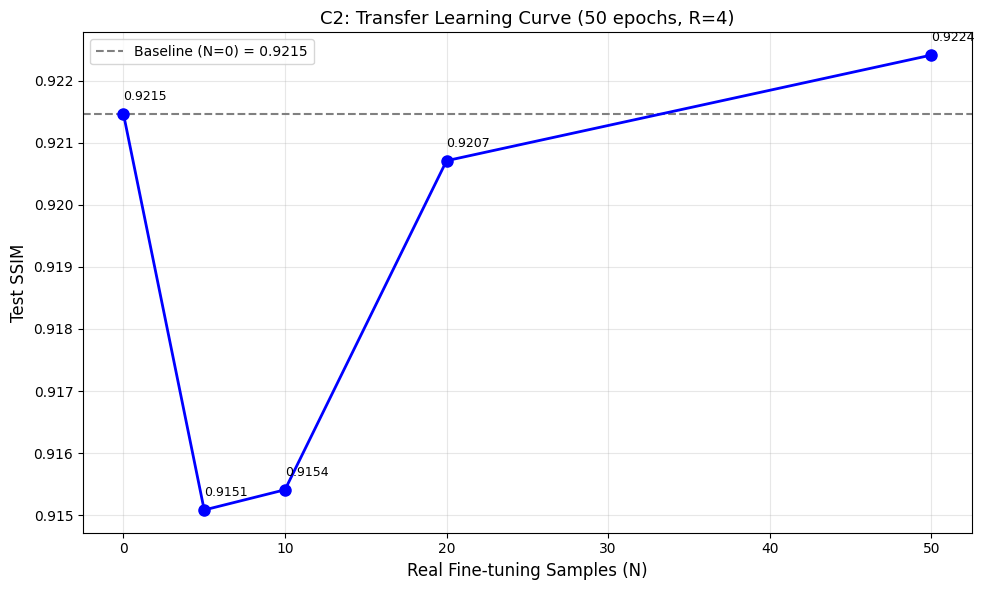

figC2_transfer.png saved


In [11]:
with open(f'{OUTPUT_DIR}/c2_transfer.json') as f:
    c2_raw = json.load(f)

# Tumhare format se convert karo
n_samples = [d['n_real'] for d in c2_raw]
ssim_c2   = [d['ssim']  for d in c2_raw]
baseline  = ssim_c2[0]

plt.figure(figsize=(10, 6))
plt.axhline(y=baseline, color='gray', linestyle='--', linewidth=1.5,
            label=f'Baseline (N=0) = {baseline:.4f}')
plt.plot(n_samples, ssim_c2, 'b-o', markersize=8, linewidth=2)
for x, y in zip(n_samples, ssim_c2):
    plt.annotate(f'{y:.4f}', (x, y),
                 textcoords="offset points", xytext=(0, 10), fontsize=9)
plt.xlabel('Real Fine-tuning Samples (N)', fontsize=12)
plt.ylabel('Test SSIM', fontsize=12)
plt.title('C2: Transfer Learning Curve (50 epochs, R=4)', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/figC2_transfer.png', dpi=150, bbox_inches='tight')
plt.show()
print("figC2_transfer.png saved")